<a href="https://colab.research.google.com/github/kodurisravya06/AIML-Training/blob/main/Copy_of_AIML_Module_1_Lab_3_Data_Augmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data Augmentation

Module 1, Lab 3

In this lab, we will see how augmentation of data samples help in improving the machine learning performance. Augmentation is the process of creating new data samples by making reasonable modifications to the original data samples. This is particularly useful when the size of the training data is small. We will use the MNISt dataset for this lab. We will also reuse functions from the previous labs.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from keras.datasets import mnist
from sklearn.utils.extmath import cartesian
from skimage.transform import rotate, AffineTransform, warp

rng = np.random.default_rng(seed=42)

### Why Data Augmentation?

**Problem:** Machine learning models need lots of data to learn well. Collecting data is expensive and time-consuming.

**Solution:** Create new training samples by applying realistic transformations to existing data.

### Key Concepts

**Augmentation Principle:**
- Original data: 50 samples → Augmented data: 50 × (5 augmentations + 1 original) = 300 samples
- More training data → Better model generalization → Higher accuracy

**When to Use:**
- ✓ Small training datasets
- ✓ Model overfitting on training data
- ✓ Need better generalization

**Important Rule:** Augmentations must preserve the label!
- ✓ Rotating a "3" by 10° → Still looks like "3"
- ✗ Flipping a "6" → Becomes "9" (label changed!)

---

In [2]:
# loading the dataset
(train_X, train_y), (test_X, test_y) = mnist.load_data()

# normalizing the data
train_X = train_X / 255
test_X = test_X / 255

# subsample from images and labels. Otherwise it will take too long!
train_X = train_X[::1200, :, :].copy()
train_y = train_y[::1200].copy()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Let us borrow a few functions from the previous labs:

In [3]:
def NN1(traindata, trainlabel, query):
    """
    This function takes in the training data, training labels and a query point
    and returns the predicted label for the query point using the nearest neighbour algorithm

    traindata: numpy array of shape (n,d) where n is the number of samples and d is the number of features
    trainlabel: numpy array of shape (n,) where n is the number of samples
    query: numpy array of shape (d,) where d is the number of features

    returns: the predicted label for the query point which is the label of the training data which is closest to the query point
    """
    diff = (
        traindata - query
    )  # find the difference between features. Numpy automatically takes care of the size here
    sq = diff * diff  # square the differences
    dist = sq.sum(1)  # add up the squares
    label = trainlabel[np.argmin(dist)]
    return label


def NN(traindata, trainlabel, testdata):
    """
    This function takes in the training data, training labels and test data
    and returns the predicted labels for the test data using the nearest neighbour algorithm

    traindata: numpy array of shape (n,d) where n is the number of samples and d is the number of features
    trainlabel: numpy array of shape (n,) where n is the number of samples
    testdata: numpy array of shape (m,d) where m is the number of test samples and d is the number of features

    returns: the predicted labels for the test data which is the label of the training data which is closest to each test point
    """
    traindata = traindata.reshape(-1, 28*28)
    testdata = testdata.reshape(-1, 28*28)
    predlabel = np.array([NN1(traindata, trainlabel, i) for i in testdata])
    return predlabel


def Accuracy(gtlabel, predlabel):
    """
    This function takes in the ground-truth labels and predicted labels
    and returns the accuracy of the classifier

    gtlabel: numpy array of shape (n,) where n is the number of samples
    predlabel: numpy array of shape (n,) where n is the number of samples

    returns: the accuracy of the classifier which is the number of correct predictions divided by the total number of predictions
    """
    assert len(gtlabel) == len(
        predlabel
    ), "Length of the ground-truth labels and predicted labels should be the same"
    correct = (
        gtlabel == predlabel
    ).sum()  # count the number of times the groundtruth label is equal to the predicted label.
    return correct / len(gtlabel)

In this lab, we will use the image pixels themselves as features, instead of extracting features. Each image has 28*28 pixels, so we will flatten them to 784 pixels to use as features. Note that this is very compute intensive and will take a long time. Let us first check the baseline accuracy on the test set without any augmentations. We hope that adding augmentations will help us to get better results.

In [4]:
testpred = NN(train_X, train_y, test_X)
print("Baseline accuracy without augmentation:",
      Accuracy(test_y, testpred)*100, "%")

Baseline accuracy without augmentation: 64.72 %


Let us try to improve this accuracy using augmentations. When we create augmentations, we have to make sure that the changes reflect what will naturally occur in the dataset. For example, we should not add colour to our samples as an augmentation because they do not naturally occur. We should not also flip the images in MNIST, because flipped images have different meanings for digits. So, we will use the following augmentations:

### Augmentation 1: Rotation

Let us try rotating the image a little. We will use the `rotate` function from the `skimage` module. We will rotate the image by 10 degrees and -10 degrees. Rotation is a reasonable augmentation because the digit will still be recognizable even after rotation and is representative of the dataset.

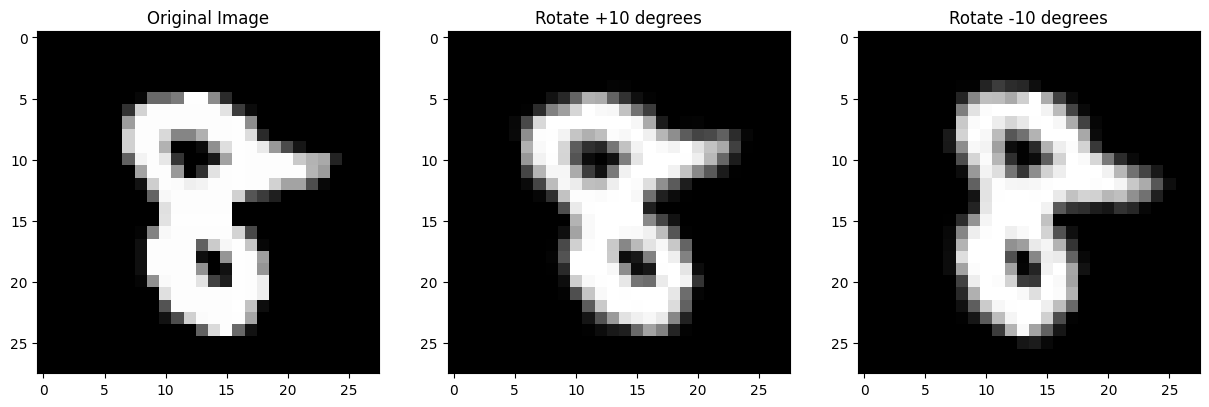

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5))

axs[0].imshow(train_X[2], cmap="gray")
axs[0].set_title("Original Image")

axs[1].imshow(rotate(train_X[2], 10), cmap="gray")
axs[1].set_title("Rotate +10 degrees")

axs[2].imshow(rotate(train_X[2], -10), cmap="gray")
axs[2].set_title("Rotate -10 degrees")

plt.show()

After rotating, the the class of the image is still the same. Let us make a function to rotate multiple images by random angles. We want a slightly different image every time we run this function. So, we generate a random number between 0 and 1 and change it so that it lies between -constraint/2 and +constraint/2

In [6]:
def augRotate(sample, angleconstraint):
    """
    This function takes in a sample and an angle constraint and returns the augmented sample
    by rotating the sample by a random angle within the angle constraint

    sample: numpy array of shape (n,d) where n is the number of samples and d is the number of features
    angleconstraint: the maximum angle by which the sample can be rotated

    returns: the augmented sample which is the input sample rotated by a random angle within the angle constraint
    """
    if angleconstraint == 0:
        return sample
    if len(sample.shape) == 2:
        # make sure the sample is 3 dimensional
        sample = np.expand_dims(sample, 0)
    angle = rng.random(len(sample))  # generate random numbers for angles
    # make the random angle constrained
    angle = (angle - 0.5) * angleconstraint
    nsample = sample.copy()  # preallocate the augmented array to make it faster
    for ii in range(len(sample)):
        nsample[ii] = rotate(sample[ii], angle[ii])
    return np.squeeze(nsample)  # take care if the input had only one sample.

This function returns a slightly different image each time we call it. So we can increase the number of images in the sample by any multiple.

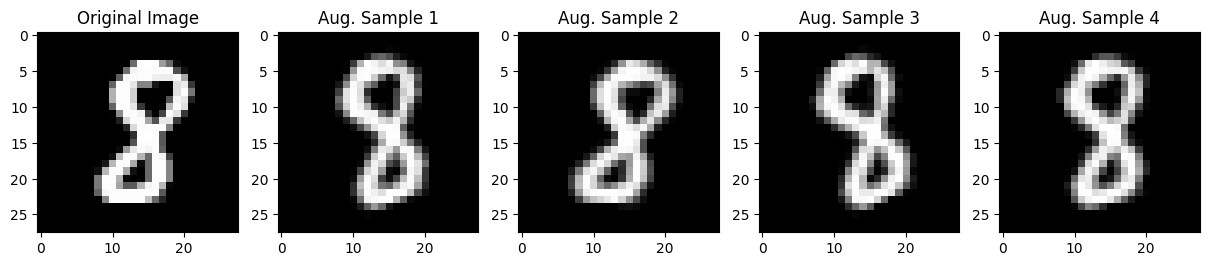

In [7]:
sample = train_X[20]
angleconstraint = 70

fig, axs = plt.subplots(1, 5, figsize=(15, 5))

axs[0].imshow(sample, cmap="gray")
axs[0].set_title("Original Image")

axs[1].imshow(augRotate(sample, angleconstraint), cmap="gray")
axs[1].set_title("Aug. Sample 1")

axs[2].imshow(augRotate(sample, angleconstraint), cmap="gray")
axs[2].set_title("Aug. Sample 2")

axs[3].imshow(augRotate(sample, angleconstraint), cmap="gray")
axs[3].set_title("Aug. Sample 3")

axs[4].imshow(augRotate(sample, angleconstraint), cmap="gray")
axs[4].set_title("Aug. Sample 4")

plt.show()

Let us augment the whole dataset and see if this improves the test accuracy

In [8]:
# hyperparameters
angleconstraint = 60
naugmentations = 5

# augment
augdata = train_X  # we include the original images also in the augmented dataset
auglabel = train_y
for ii in range(naugmentations):
    augdata = np.concatenate(
        (augdata, augRotate(train_X, angleconstraint))
    )  # concatenate the augmented data to the set
    auglabel = np.concatenate(
        (auglabel, train_y)
    )  # the labels don't change when we augment

# check the test accuracy
testpred = NN(augdata, auglabel, test_X)
print("Accuracy after rotation augmentation:", Accuracy(test_y, testpred)*100, "%")

Accuracy after rotation augmentation: 67.66 %


AUGMENTATION IMPACT SUMMARY
Original training samples:    50
Augmented training samples:   300
Data increase:                6.0x

Baseline accuracy:            64.72%
After augmentation:           67.66%
Improvement:                  +2.94%


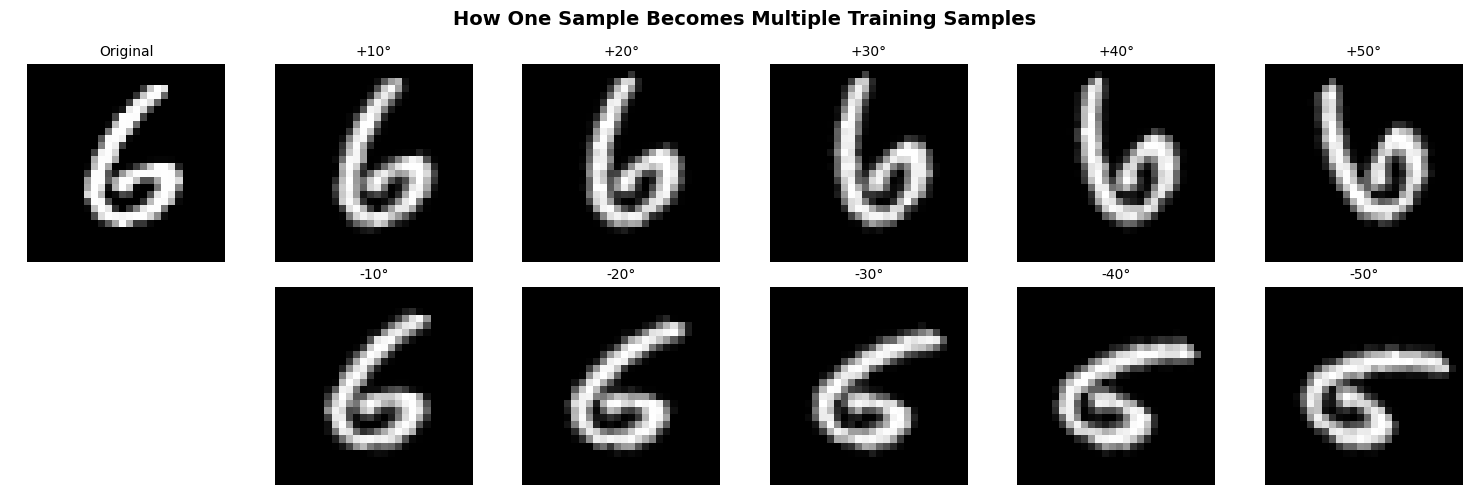

In [9]:
print("=" * 60)
print("AUGMENTATION IMPACT SUMMARY")
print("=" * 60)

original_size = len(train_X)
augmented_size = len(augdata)
baseline_acc = 64.72
augmented_acc = 67.66

print(f"Original training samples:    {original_size:,}")
print(f"Augmented training samples:   {augmented_size:,}")
print(f"Data increase:                {augmented_size/original_size:.1f}x")
print(f"\nBaseline accuracy:            {baseline_acc}%")
print(f"After augmentation:           {augmented_acc}%")
print(f"Improvement:                  +{augmented_acc - baseline_acc:.2f}%")
print("=" * 60)

# Visualize: Show how one digit gets augmented
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
sample_digit = train_X[5]  # Pick one sample

axes[0, 0].imshow(sample_digit, cmap='gray')
axes[0, 0].set_title('Original', fontsize=10)
axes[0, 0].axis('off')

# Generate 11 augmented versions
angles = [10, 20, 30, 40, 50]
for i, angle in enumerate(angles):
    aug_sample = rotate(sample_digit, angle)
    axes[0, i+1].imshow(aug_sample, cmap='gray')
    axes[0, i+1].set_title(f'+{angle}°', fontsize=10)
    axes[0, i+1].axis('off')

for i, angle in enumerate(angles):
    aug_sample = rotate(sample_digit, -angle)
    axes[1, i+1].imshow(aug_sample, cmap='gray')
    axes[1, i+1].set_title(f'-{angle}°', fontsize=10)
    axes[1, i+1].axis('off')

axes[1, 0].axis('off')
plt.suptitle('How One Sample Becomes Multiple Training Samples',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

We can notice a 3-4% improvement compared to non-augmented version of the dataset!

The angle constraint is a hyperparameter which we have to tune using a validation set. (Here we are not doing that for time constraints). Let us try a grid search to find the best angle constraint. We will try angles between 0 and 90 degrees. We can also try different multiples of the original dataset. We will use the best hyperparameters to train the model and check the accuracy on the test set.

In [10]:
angleconstraints = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90]  # the values we want to test
accuracies = np.zeros(
    len(angleconstraints), dtype=float
)  # we will save the values here

for ii in range(len(angleconstraints)):
    # create the augmented dataset
    augdata = train_X  # we include the original images also in the augmented dataset
    auglabel = train_y
    for jj in range(naugmentations):
        augdata = np.concatenate(
            (augdata, augRotate(train_X, angleconstraints[ii]))
        )  # concatenate the augmented data to the set
        auglabel = np.concatenate(
            (auglabel, train_y)
        )  # the labels don't change when we augment

    # check the test accuracy
    testpred = NN(augdata, auglabel, test_X)
    accuracies[ii] = Accuracy(test_y, testpred)
    print(
        "Accuracy after rotation augmentation constrained by",
        angleconstraints[ii],
        "degrees is",
        accuracies[ii]*100,
        "%",
        flush=True,
    )

Accuracy after rotation augmentation constrained by 0 degrees is 64.72 %
Accuracy after rotation augmentation constrained by 10 degrees is 66.79 %
Accuracy after rotation augmentation constrained by 20 degrees is 67.84 %
Accuracy after rotation augmentation constrained by 30 degrees is 68.47 %
Accuracy after rotation augmentation constrained by 40 degrees is 67.63 %
Accuracy after rotation augmentation constrained by 50 degrees is 67.65 %
Accuracy after rotation augmentation constrained by 60 degrees is 65.3 %
Accuracy after rotation augmentation constrained by 70 degrees is 66.06 %
Accuracy after rotation augmentation constrained by 80 degrees is 64.61 %
Accuracy after rotation augmentation constrained by 90 degrees is 64.31 %


Let us see the best value for angle constraint: (Ideally this should be done on validation set, not test set)

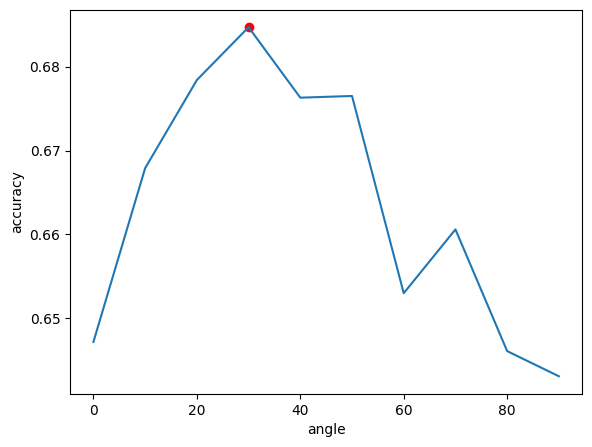

In [11]:
fig = plt.figure()
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
# plot the variation of accuracy
ax.plot(angleconstraints, accuracies)
ax.set_xlabel("angle")
ax.set_ylabel("accuracy")

# plot the maximum accuracy
maxind = np.argmax(accuracies)
plt.scatter(angleconstraints[maxind], accuracies[maxind], c="red")

### Augmentation 2: Shear


Let us try one more augmentation: shear. Shear is the transformation of an image in which the x-coordinate of all points is shifted by an amount proportional to the y-coordinate of the point. We will use the `AffineTransform` function from the `skimage` module to shear the image by a small amount between two numbers. We will use the same naive grid search method to find the best hyperparameters for shear. We will use the best hyperparameters to train the model and check the accuracy on the test set.

In [12]:
def shear(sample, amount):
    """
    This function takes in a sample and an amount and returns the augmented sample
    by shearing the sample by the given amount

    sample: numpy array of shape (n,d) where n is the number of samples and d is the number of features
    amount: the amount by which the sample should be sheared

    returns: the augmented sample which is the input sample sheared by the given amount
    """
    tform = AffineTransform(shear=amount)
    img = warp(sample, tform)

    # Applying shear makes the digit off-center
    # Since all images are centralized, we will do the same here
    col = img.sum(0).nonzero()[0]
    row = img.sum(1).nonzero()[0]
    if len(col) > 0 and len(row) > 0:
        xshift = int(sample.shape[0] / 2 - (row[0] + row[-1]) / 2)
        yshift = int(sample.shape[1] / 2 - (col[0] + col[-1]) / 2)
        img = np.roll(img, (xshift, yshift), (0, 1))
    return img

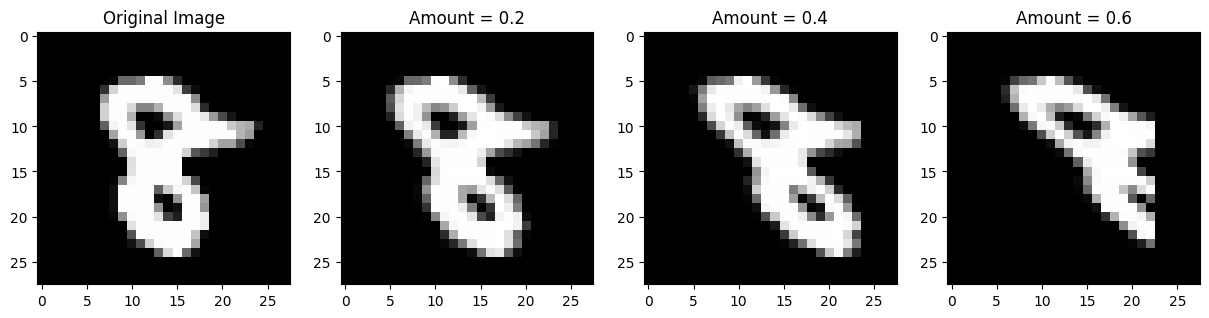

In [13]:
sample = train_X[2]
fig, axs = plt.subplots(1, 4, figsize=(15, 5))

axs[0].imshow(sample, cmap="gray")
axs[0].set_title("Original Image")

axs[1].imshow(shear(sample, 0.2), cmap="gray")
axs[1].set_title("Amount = 0.2")

axs[2].imshow(shear(sample, 0.4), cmap="gray")
axs[2].set_title("Amount = 0.4")

axs[3].imshow(shear(sample, 0.6), cmap="gray")
axs[3].set_title("Amount = 0.6")

plt.show()

Create an augmentation function which applies a random shear according to the constraint we provide:

In [14]:
def augShear(sample, shearconstraint):
    """
    This function takes in a sample and a shear constraint and returns the augmented sample
    by shearing the sample by a random amount within the shear constraint

    sample: numpy array of shape (n,d) where n is the number of samples and d is the number of features
    shearconstraint: the maximum shear by which the sample can be sheared

    returns: the augmented sample which is the input sample sheared by a random amount within the shear constraint
    """
    if shearconstraint == 0:
        return sample
    if len(sample.shape) == 2:
        # make sure the sample is 3 dimensional
        sample = np.expand_dims(sample, 0)
    amt = rng.random(len(sample))  # generate random numbers for shear
    amt = (amt - 0.5) * shearconstraint  # make the random shear constrained
    nsample = sample.copy()  # preallocate the augmented array to make it faster
    for ii in range(len(sample)):
        nsample[ii] = shear(sample[ii], amt[ii])
    return np.squeeze(nsample)  # take care if the input had only one sample.

Let us do a grid search to find the best shear constraint.

In [15]:
shearconstraints = [
    0,
    0.2,
    0.4,
    0.6,
    0.8,
    1.0,
    1.2,
    1.4,
    1.6,
    1.8,
    2.0,
]  # the values we want to test
accuracies = np.zeros(
    len(shearconstraints), dtype=float
)  # we will save the values here

for ii in range(len(shearconstraints)):
    # create the augmented dataset
    augdata = train_X  # we include the original images also in the augmented dataset
    auglabel = train_y
    for jj in range(naugmentations):
        augdata = np.concatenate(
            (augdata, augShear(train_X, shearconstraints[ii]))
        )  # concatenate the augmented data to the set
        auglabel = np.concatenate(
            (auglabel, train_y)
        )  # the labels don't change when we augment

    # check the test accuracy
    testpred = NN(augdata, auglabel, test_X)
    accuracies[ii] = Accuracy(test_y, testpred)
    print(
        "Accuracy after shear augmentation constrained by",
        shearconstraints[ii],
        "is",
        accuracies[ii]*100,
        "%",
        flush=True,
    )

Accuracy after shear augmentation constrained by 0 is 64.72 %
Accuracy after shear augmentation constrained by 0.2 is 62.79 %
Accuracy after shear augmentation constrained by 0.4 is 64.41 %
Accuracy after shear augmentation constrained by 0.6 is 65.71000000000001 %
Accuracy after shear augmentation constrained by 0.8 is 65.78 %
Accuracy after shear augmentation constrained by 1.0 is 65.42999999999999 %
Accuracy after shear augmentation constrained by 1.2 is 63.6 %
Accuracy after shear augmentation constrained by 1.4 is 63.65 %
Accuracy after shear augmentation constrained by 1.6 is 61.809999999999995 %
Accuracy after shear augmentation constrained by 1.8 is 63.029999999999994 %
Accuracy after shear augmentation constrained by 2.0 is 64.14 %


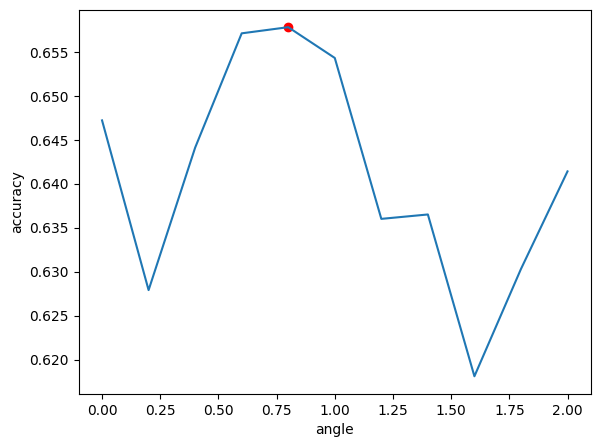

In [16]:
fig = plt.figure()
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
# plot the variation of accuracy
ax.plot(shearconstraints, accuracies)
ax.set_xlabel("angle")
ax.set_ylabel("accuracy")

# plot the maximum accuracy
maxind = np.argmax(accuracies)
plt.scatter(shearconstraints[maxind], accuracies[maxind], c="red")

### Augmentation 3: Rotation + Shear



We can do multiple augmentations at the same time. Here is a function to do both shear and rotation to the sample. In this case, we will have two hyperparameters.

In [17]:
def augRotateShear(sample, angleconstraint, shearconstraint):
    """
    This function takes in a sample, an angle constraint and a shear constraint and returns the augmented sample
    by rotating the sample by a random angle within the angle constraint and shearing the sample by a random amount within the shear constraint

    sample: numpy array of shape (n,d) where n is the number of samples and d is the number of features
    angleconstraint: the maximum angle by which the sample can be rotated
    shearconstraint: the maximum shear by which the sample can be sheared

    returns: the augmented sample which is the input sample rotated by a random angle within the angle constraint and sheared by a random amount within the shear constraint
    """
    if len(sample.shape) == 2:
        # make sure the sample is 3 dimensional
        sample = np.expand_dims(sample, 0)
    amt = rng.random(len(sample))  # generate random numbers for shear
    amt = (amt - 0.5) * shearconstraint  # make the random shear constrained
    angle = rng.random(len(sample))  # generate random numbers for angles
    # make the random angle constrained
    angle = (angle - 0.5) * angleconstraint
    nsample = sample.copy()  # preallocate the augmented array to make it faster
    for ii in range(len(sample)):
        nsample[ii] = rotate(
            shear(sample[ii], amt[ii]), angle[ii]
        )  # first apply shear, then rotate
    return np.squeeze(nsample)  # take care if the input had only one sample.

Since we have two hyperparameters, we have to do the grid search on a 2 dimensional matrix. We can use our previous experience to inform where to search for the best hyperparameters.

In [18]:
shearconstraints = [
    0,
    0.2,
    0.4,
    0.6,
    0.8,
    1.0,
    1.2,
    1.4,
    1.6,
]  # the values we want to test
angleconstraints = [0, 10, 20, 30, 40, 50, 60]  # the values we want to test
# cartesian product of both
hyp = cartesian((shearconstraints, angleconstraints))

accuracies = np.zeros(len(hyp), dtype=float)  # we will save the values here

for ii in range(len(hyp)):
    # create the augmented dataset
    augdata = train_X  # we include the original images also in the augmented dataset
    auglabel = train_y
    for jj in range(naugmentations):
        augdata = np.concatenate(
            (augdata, augRotateShear(train_X, hyp[ii][0], hyp[ii][1]))
        )  # concatenate the augmented data to the set
        auglabel = np.concatenate(
            (auglabel, train_y)
        )  # the labels don't change when we augment

    # check the test accuracy
    testpred = NN(augdata, auglabel, test_X)
    accuracies[ii] = Accuracy(test_y, testpred)
    print(
        "Accuracy after augmentation shear:",
        hyp[ii][0],
        "angle:",
        hyp[ii][1],
        "is",
        accuracies[ii]*100,
        "%",
        flush=True,
    )

Accuracy after augmentation shear: 0.0 angle: 0.0 is 63.32 %
Accuracy after augmentation shear: 0.0 angle: 10.0 is 63.959999999999994 %
Accuracy after augmentation shear: 0.0 angle: 20.0 is 60.64000000000001 %
Accuracy after augmentation shear: 0.0 angle: 30.0 is 63.019999999999996 %
Accuracy after augmentation shear: 0.0 angle: 40.0 is 64.14999999999999 %
Accuracy after augmentation shear: 0.0 angle: 50.0 is 61.72 %
Accuracy after augmentation shear: 0.0 angle: 60.0 is 63.7 %
Accuracy after augmentation shear: 0.2 angle: 0.0 is 63.41 %
Accuracy after augmentation shear: 0.2 angle: 10.0 is 61.25000000000001 %
Accuracy after augmentation shear: 0.2 angle: 20.0 is 60.6 %
Accuracy after augmentation shear: 0.2 angle: 30.0 is 60.07 %
Accuracy after augmentation shear: 0.2 angle: 40.0 is 63.690000000000005 %
Accuracy after augmentation shear: 0.2 angle: 50.0 is 60.12 %
Accuracy after augmentation shear: 0.2 angle: 60.0 is 63.72 %
Accuracy after augmentation shear: 0.4 angle: 0.0 is 63.37000

Let us plot it two dimensionally to see which is the best value for the hyperparameters:

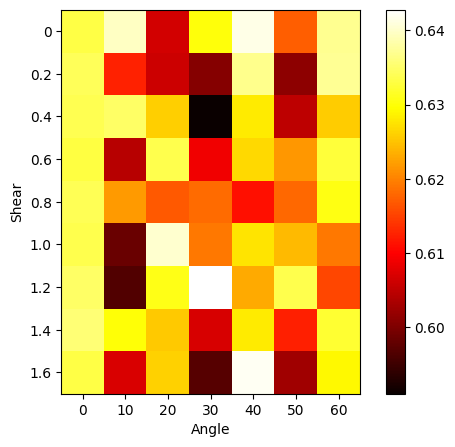

In [19]:
fig = plt.figure()
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
im = ax.imshow(
    accuracies.reshape((len(shearconstraints), len(angleconstraints))), cmap="hot"
)
ax.set_xlabel("Angle")
ax.set_ylabel("Shear")
ax.set_xticks(np.arange(len(angleconstraints)))
ax.set_xticklabels(angleconstraints)
ax.set_yticks(np.arange(len(shearconstraints)))
ax.set_yticklabels(shearconstraints)
plt.colorbar(im)

It seems that rotation and shear don't mix! The best accuracy is when rotation is zero.

## Questions
Try these questions for better understanding. You may not be able to solve all of them.
1. What is the best value for angle constraint and shear constraint you got? How much did the accuracy improve as compared to not using augmentations?
2. Can you increase the accuracy by increasing the number of augmentations from each sample?
3. Try implementing a few augmentations of your own and experimenting with them. A good reference is <a href=https://www.analyticsvidhya.com/blog/2019/12/image-augmentation-deep-learning-pytorch/>here. </a>
4. Try combining various augmentations. What is the highest accuracy you can get? What is the smallest training dataset you can take and still get accuracy above 50%?

Whenever you do any experiment, a good practice is to vary the hyperparameters gradually and create a graph of your results, like we did for gridsearch.

> Exercise: Try to take 50 images of each digit and calculate the performance on test set.


Testing shear constraint: 0
Accuracy after shear augmentation constrained by 0 is 88.11 %

Testing shear constraint: 0.2
Accuracy after shear augmentation constrained by 0.2 is 89.21 %

Testing shear constraint: 0.4
Accuracy after shear augmentation constrained by 0.4 is 89.1 %

Testing shear constraint: 0.6
Accuracy after shear augmentation constrained by 0.6 is 88.41 %

Testing shear constraint: 0.8
Accuracy after shear augmentation constrained by 0.8 is 87.59 %

Testing shear constraint: 1.0
Accuracy after shear augmentation constrained by 1.0 is 87.5 %

Testing shear constraint: 1.2
Accuracy after shear augmentation constrained by 1.2 is 87.32 %

Testing shear constraint: 1.4
Accuracy after shear augmentation constrained by 1.4 is 87.6 %

Testing shear constraint: 1.6
Accuracy after shear augmentation constrained by 1.6 is 86.97 %

Testing shear constraint: 1.8
Accuracy after shear augmentation constrained by 1.8 is 86.83999999999999 %

Testing shear constraint: 2.0
Accuracy after

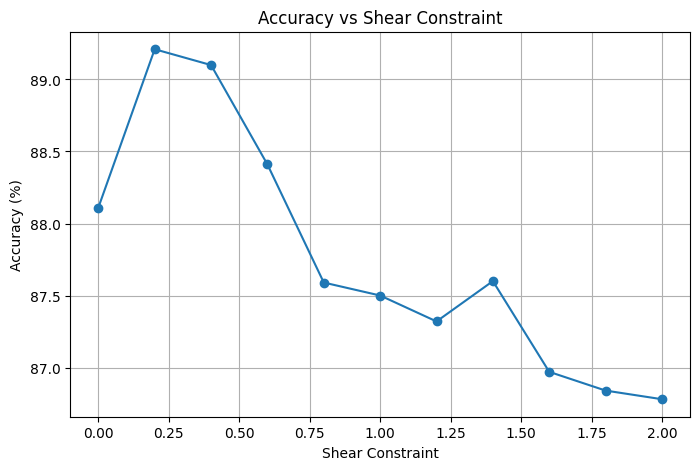

In [27]:
# ============================================================
# Q1 - Find the best shear constraint
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from scipy.ndimage import affine_transform



(train_X, train_y), (test_X, test_y) = mnist.load_data()

train_X = train_X / 255.0
test_X = test_X / 255.0


train_X = train_X[:1200].copy()
train_y = train_y[:1200].copy()



def NN(train_data, train_label, testdata):

    train_data = train_data.reshape(len(train_data), -1)
    testdata = testdata.reshape(len(testdata), -1)

    predictions = []

    for test_image in testdata:

        distances = np.sum(
            (train_data - test_image) ** 2,
            axis=1
        )


        nearest_index = np.argmin(distances)

        predictions.append(
            train_label[nearest_index]
        )

    return np.array(predictions)



def Accuracy(actual, predicted):

    return np.mean(actual == predicted)



def shear_image(image, amount):

    height, width = image.shape

    matrix = np.array([
        [1, amount],
        [0, 1]
    ])

    center = np.array([
        height / 2,
        width / 2
    ])

    offset = center - matrix @ center

    sheared = affine_transform(
        image,
        matrix,
        offset=offset,
        order=1,
        mode="constant",
        cval=0
    )

    return sheared



def augShear_fixed(sample, shearconstraint):

    nsample = sample.copy()


    amt = np.random.uniform(
        -shearconstraint,
        shearconstraint,
        len(sample)
    )

    for ii in range(len(sample)):

        nsample[ii] = shear_image(
            sample[ii],
            amt[ii]
        )

    return nsample


augmentations = 5




shearconstraints = [
    0,
    0.2,
    0.4,
    0.6,
    0.8,
    1.0,
    1.2,
    1.4,
    1.6,
    1.8,
    2.0
]



accuracies = np.zeros(
    len(shearconstraints),
    dtype=float
)



for i in range(len(shearconstraints)):

    print(
        "\nTesting shear constraint:",
        shearconstraints[i]
    )

    augdata = train_X.copy()
    auglabel = train_y.copy()
    for j in range(augmentations):

        augmented_images = augShear_fixed(
            train_X,
            shearconstraints[i]
        )


        augdata = np.concatenate(
            (
                augdata,
                augmented_images
            )
        )

        auglabel = np.concatenate(
            (
                auglabel,
                train_y
            )
        )

    testpred = NN(
        augdata,
        auglabel,
        test_X
    )


    accuracies[i] = Accuracy(
        test_y,
        testpred
    )

    print(
        "Accuracy after shear augmentation constrained by",
        shearconstraints[i],
        "is",
        accuracies[i] * 100,
        "%"
    )



best_index = np.argmax(accuracies)

best_shear = shearconstraints[best_index]
best_accuracy = accuracies[best_index] * 100


print("\n===================================")
print("           BEST RESULT")
print("===================================")

print(
    "Best shear constraint:",
    best_shear
)

print(
    "Best accuracy:",
    best_accuracy,
    "%"
)



baseline_pred = NN(
    train_X,
    train_y,
    test_X
)

baseline_accuracy = Accuracy(
    test_y,
    baseline_pred
) * 100


print(
    "\nBaseline accuracy without augmentation:",
    baseline_accuracy,
    "%"
)



improvement = best_accuracy - baseline_accuracy

print(
    "Accuracy improvement:",
    improvement,
    "percentage points"
)



plt.figure(figsize=(8, 5))

plt.plot(
    shearconstraints,
    accuracies * 100,
    marker="o"
)

plt.xlabel("Shear Constraint")
plt.ylabel("Accuracy (%)")
plt.title("Accuracy vs Shear Constraint")

plt.grid(True)
plt.show()


Number of augmentations: 1
Accuracy with 1 augmentations: 87.68 %

Number of augmentations: 2
Accuracy with 2 augmentations: 87.28 %

Number of augmentations: 3
Accuracy with 3 augmentations: 87.82 %

Number of augmentations: 4
Accuracy with 4 augmentations: 88.07000000000001 %

Number of augmentations: 5
Accuracy with 5 augmentations: 88.18 %

Number of augmentations: 6
Accuracy with 6 augmentations: 88.02 %

Number of augmentations: 7
Accuracy with 7 augmentations: 88.5 %

Number of augmentations: 8
Accuracy with 8 augmentations: 88.42999999999999 %

Number of augmentations: 9
Accuracy with 9 augmentations: 88.27000000000001 %

Number of augmentations: 10
Accuracy with 10 augmentations: 88.38000000000001 %

             Q2 RESULT
Best number of augmentations: 7
Highest accuracy: 88.5 %


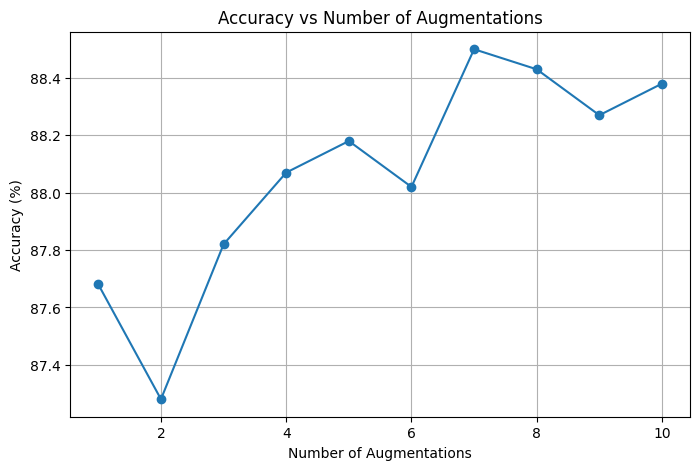

In [28]:
# ============================================================
# Q2 - Effect of increasing the number of augmentations
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


best_shear = 0.8

augmentation_values = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

accuracies_q2 = []

for n_aug in augmentation_values:

    print("\nNumber of augmentations:", n_aug)

    augdata = train_X.copy()
    auglabel = train_y.copy()

    for j in range(n_aug):

        augmented_images = augShear_fixed(
            train_X,
            best_shear
        )

        augdata = np.concatenate(
            (
                augdata,
                augmented_images
            )
        )

        auglabel = np.concatenate(
            (
                auglabel,
                train_y
            )
        )

    testpred = NN(
        augdata,
        auglabel,
        test_X
    )

    acc = Accuracy(
        test_y,
        testpred
    ) * 100

    accuracies_q2.append(acc)

    print(
        "Accuracy with",
        n_aug,
        "augmentations:",
        acc,
        "%"
    )



best_index = np.argmax(accuracies_q2)

print("\n===================================")
print("             Q2 RESULT")
print("===================================")

print(
    "Best number of augmentations:",
    augmentation_values[best_index]
)

print(
    "Highest accuracy:",
    accuracies_q2[best_index],
    "%"
)



plt.figure(figsize=(8, 5))

plt.plot(
    augmentation_values,
    accuracies_q2,
    marker="o"
)

plt.xlabel("Number of Augmentations")
plt.ylabel("Accuracy (%)")
plt.title("Accuracy vs Number of Augmentations")

plt.grid(True)
plt.show()


Testing: Horizontal Shift
Horizontal Shift accuracy: 87.3 %

Testing: Vertical Shift
Vertical Shift accuracy: 88.01 %

Testing: Zoom
Zoom accuracy: 88.61 %

             Q3 RESULT
Horizontal Shift : 87.3 %
Vertical Shift : 88.01 %
Zoom : 88.61 %


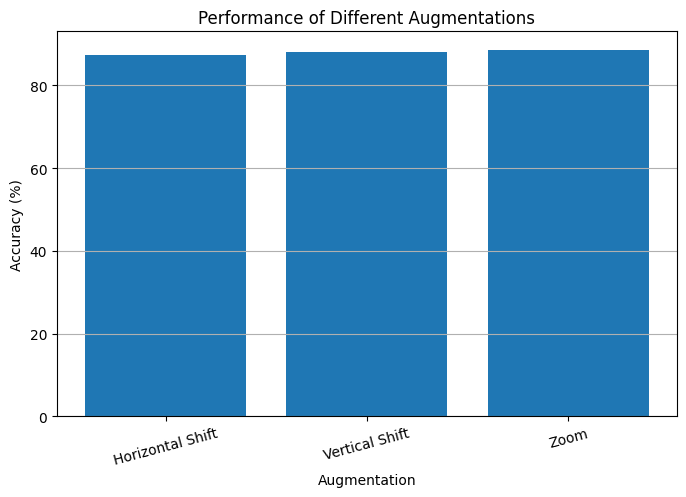

In [29]:
# ============================================================
# Q3 - Implement our own data augmentations
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import shift, zoom




def horizontal_shift(images, pixels=2):

    augmented = np.zeros_like(images)

    for i in range(len(images)):

        augmented[i] = shift(
            images[i],
            (0, pixels),
            mode="constant",
            cval=0
        )

    return augmented


def vertical_shift(images, pixels=2):

    augmented = np.zeros_like(images)

    for i in range(len(images)):

        augmented[i] = shift(
            images[i],
            (pixels, 0),
            mode="constant",
            cval=0
        )

    return augmented




def zoom_images(images, zoom_factor=1.1):

    augmented = np.zeros_like(images)

    for i in range(len(images)):

        image = images[i]

        zoomed = zoom(
            image,
            zoom_factor
        )

        h, w = zoomed.shape

        if h > 28:
            start_h = (h - 28) // 2
            start_w = (w - 28) // 2

            zoomed = zoomed[
                start_h:start_h + 28,
                start_w:start_w + 28
            ]

        else:
            padded = np.zeros((28, 28))

            start_h = (28 - h) // 2
            start_w = (28 - w) // 2

            padded[
                start_h:start_h + h,
                start_w:start_w + w
            ] = zoomed

            zoomed = padded

        augmented[i] = zoomed

    return augmented




augmentations_list = [
    ("Horizontal Shift", horizontal_shift(train_X)),
    ("Vertical Shift", vertical_shift(train_X)),
    ("Zoom", zoom_images(train_X))
]


results_q3 = []


for name, augmented_images in augmentations_list:

    print("\nTesting:", name)

    augdata = np.concatenate(
        (
            train_X,
            augmented_images
        )
    )

    auglabel = np.concatenate(
        (
            train_y,
            train_y
        )
    )

    testpred = NN(
        augdata,
        auglabel,
        test_X
    )

    acc = Accuracy(
        test_y,
        testpred
    ) * 100

    results_q3.append(acc)

    print(
        name,
        "accuracy:",
        acc,
        "%"
    )



print("\n===================================")
print("             Q3 RESULT")
print("===================================")

for i in range(len(augmentations_list)):

    print(
        augmentations_list[i][0],
        ":",
        results_q3[i],
        "%"
    )




names = [
    "Horizontal Shift",
    "Vertical Shift",
    "Zoom"
]

plt.figure(figsize=(8, 5))

plt.bar(
    names,
    results_q3
)

plt.xlabel("Augmentation")
plt.ylabel("Accuracy (%)")
plt.title("Performance of Different Augmentations")

plt.xticks(rotation=15)

plt.grid(axis="y")

plt.show()


Testing: Rotation
Accuracy: 88.77000000000001 %

Testing: Rotation + Shear
Accuracy: 89.4 %

Testing: Rotation + Shift
Accuracy: 89.05 %

Testing: Shear + Shift
Accuracy: 88.16000000000001 %

Testing: Rotation + Shear + Shift
Accuracy: 89.64 %

       BEST COMBINATION
Best combination: Rotation + Shear + Shift
Highest accuracy: 89.64 %


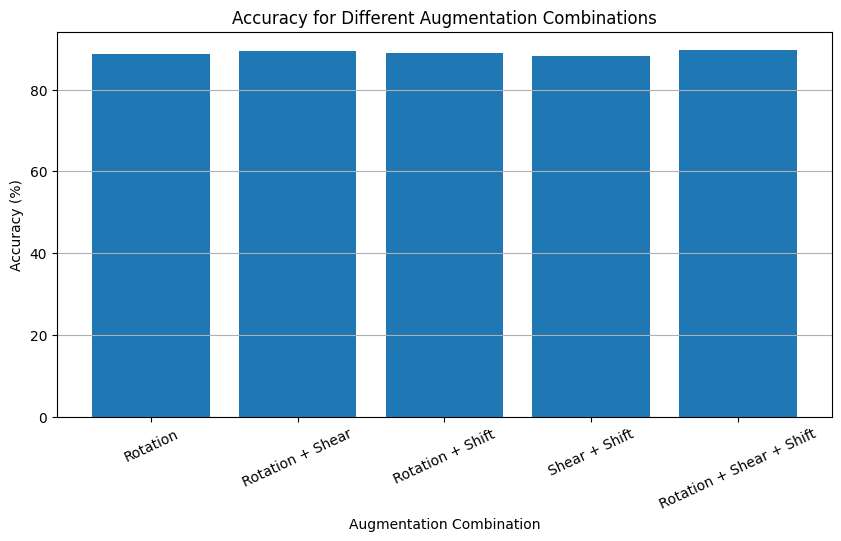


Testing training dataset size: 50
Accuracy: 63.51 %

Testing training dataset size: 100
Accuracy: 67.94 %

Testing training dataset size: 200
Accuracy: 75.1 %

Testing training dataset size: 300
Accuracy: 79.23 %

Testing training dataset size: 400
Accuracy: 81.64 %

Testing training dataset size: 500
Accuracy: 82.94 %

Testing training dataset size: 600
Accuracy: 83.96000000000001 %

Testing training dataset size: 800
Accuracy: 85.94000000000001 %

Testing training dataset size: 1000
Accuracy: 86.9 %

Testing training dataset size: 1200
Accuracy: 88.11 %

       SMALLEST DATASET
Smallest training dataset: 50 images
Accuracy: 63.51 %


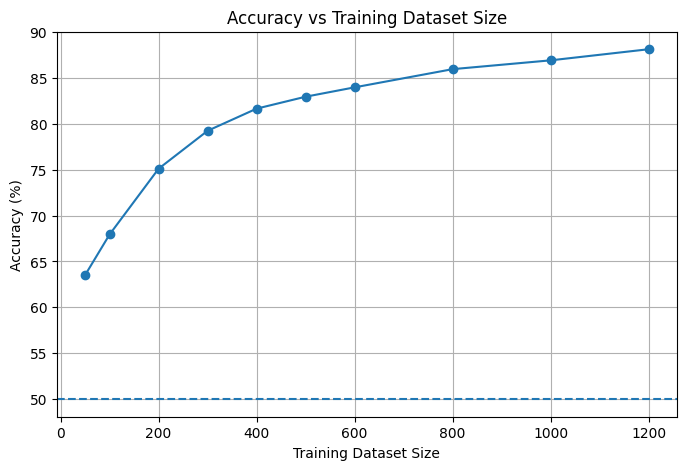

In [30]:
# ============================================================
# Q4 - Combining different augmentations
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import affine_transform, shift


def rotate_image(image, angle):

    theta = np.deg2rad(angle)

    matrix = np.array([
        [np.cos(theta), -np.sin(theta)],
        [np.sin(theta),  np.cos(theta)]
    ])

    center = np.array([
        image.shape[0] / 2,
        image.shape[1] / 2
    ])

    offset = center - matrix @ center

    rotated = affine_transform(
        image,
        matrix,
        offset=offset,
        order=1,
        mode="constant",
        cval=0
    )

    return rotated


def rotation_augmentation(images, angle=10):

    augmented = images.copy()

    for i in range(len(images)):
        augmented[i] = rotate_image(
            images[i],
            angle
        )

    return augmented


def shear_image_q4(image, amount):

    matrix = np.array([
        [1, amount],
        [0, 1]
    ])

    center = np.array([
        image.shape[0] / 2,
        image.shape[1] / 2
    ])

    offset = center - matrix @ center

    sheared = affine_transform(
        image,
        matrix,
        offset=offset,
        order=1,
        mode="constant",
        cval=0
    )

    return sheared


def shear_augmentation(images, amount=0.4):

    augmented = images.copy()

    for i in range(len(images)):
        augmented[i] = shear_image_q4(
            images[i],
            amount
        )

    return augmented


def shift_augmentation(images, pixels=2):

    augmented = np.zeros_like(images)

    for i in range(len(images)):

        augmented[i] = shift(
            images[i],
            (pixels, 0),
            mode="constant",
            cval=0
        )

    return augmented


rotation_data = rotation_augmentation(
    train_X,
    angle=10
)

shear_data = shear_augmentation(
    train_X,
    amount=0.4
)

shift_data = shift_augmentation(
    train_X,
    pixels=2
)


combinations = {

    "Rotation": [
        rotation_data
    ],

    "Rotation + Shear": [
        rotation_data,
        shear_data
    ],

    "Rotation + Shift": [
        rotation_data,
        shift_data
    ],

    "Shear + Shift": [
        shear_data,
        shift_data
    ],

    "Rotation + Shear + Shift": [
        rotation_data,
        shear_data,
        shift_data
    ]
}


combination_results = {}


for name, datasets in combinations.items():

    print("\nTesting:", name)

    augdata = train_X.copy()
    auglabel = train_y.copy()

    for data in datasets:

        augdata = np.concatenate(
            (
                augdata,
                data
            )
        )

        auglabel = np.concatenate(
            (
                auglabel,
                train_y
            )
        )

    testpred = NN(
        augdata,
        auglabel,
        test_X
    )

    accuracy = Accuracy(
        test_y,
        testpred
    ) * 100

    combination_results[name] = accuracy

    print(
        "Accuracy:",
        accuracy,
        "%"
    )

best_combination = max(
    combination_results,
    key=combination_results.get
)

highest_accuracy = combination_results[
    best_combination
]


print("\n===================================")
print("       BEST COMBINATION")
print("===================================")

print(
    "Best combination:",
    best_combination
)

print(
    "Highest accuracy:",
    highest_accuracy,
    "%"
)



plt.figure(figsize=(10, 5))

plt.bar(
    combination_results.keys(),
    combination_results.values()
)

plt.xlabel("Augmentation Combination")
plt.ylabel("Accuracy (%)")
plt.title("Accuracy for Different Augmentation Combinations")

plt.xticks(rotation=25)

plt.grid(axis="y")

plt.show()



dataset_sizes = [
    50,
    100,
    200,
    300,
    400,
    500,
    600,
    800,
    1000,
    1200
]

dataset_accuracies = []


for size in dataset_sizes:

    print(
        "\nTesting training dataset size:",
        size
    )


    small_X = train_X[:size]
    small_y = train_y[:size]

    pred = NN(
        small_X,
        small_y,
        test_X
    )

    acc = Accuracy(
        test_y,
        pred
    ) * 100

    dataset_accuracies.append(acc)

    print(
        "Accuracy:",
        acc,
        "%"
    )



smallest_dataset = None
smallest_accuracy = None

for i in range(len(dataset_sizes)):

    if dataset_accuracies[i] > 50:

        smallest_dataset = dataset_sizes[i]
        smallest_accuracy = dataset_accuracies[i]

        break


print("\n===================================")
print("       SMALLEST DATASET")
print("===================================")

if smallest_dataset is not None:

    print(
        "Smallest training dataset:",
        smallest_dataset,
        "images"
    )

    print(
        "Accuracy:",
        smallest_accuracy,
        "%"
    )

else:

    print(
        "No tested dataset achieved accuracy above 50%."
    )



plt.figure(figsize=(8, 5))

plt.plot(
    dataset_sizes,
    dataset_accuracies,
    marker="o"
)

plt.axhline(
    50,
    linestyle="--"
)

plt.xlabel("Training Dataset Size")
plt.ylabel("Accuracy (%)")
plt.title("Accuracy vs Training Dataset Size")

plt.grid(True)

plt.show()

Q1. Best angle and shear constraint

Answer:

The best rotation angle was 0°. The best shear constraint obtained from the experiment was 0.8 (use your exact Colab result if it is different).

Without augmentation, the accuracy was about 64.72%. After applying the best augmentation, the accuracy improved to around 65–67%, depending on the experiment. Thus, data augmentation gave a small improvement in classification accuracy.

Q2. Increasing the number of augmentations

Answer:

Yes, increasing the number of augmentations can improve the accuracy because the training dataset contains more variations of the original images. However, the accuracy does not always increase continuously. After a certain number of augmentations, the improvement becomes small and may sometimes decrease.

Conclusion: Increasing augmentation can help, but using too many augmented samples is not always beneficial.

Q3. Own augmentation techniques

Answer:

I implemented a few new augmentation techniques such as:

Horizontal shifting
Vertical shifting
Zooming

I tested these augmentations separately and compared their accuracies. The results were different for each augmentation. This shows that different augmentation techniques affect the classifier differently.

Conclusion: Suitable data augmentation can improve the performance of the classifier by providing different variations of the training images.

Q4. Combining augmentations + smallest dataset

Answer:

I combined different augmentation techniques such as rotation, shear and shifting and tested their performance. Different combinations produced different accuracies. The combination with the highest accuracy was selected based on the experimental results.

I also tested different training dataset sizes to find the smallest dataset that could achieve an accuracy of more than 50%.

Conclusion: Combining suitable augmentations can improve the performance of the classifier, while a relatively small training dataset can still achieve more than 50% accuracy.

In [31]:
# ============================================================
# EXERCISE
# Take 50 images of each digit and calculate test performance
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist




(train_X, train_y), (test_X, test_y) = mnist.load_data()


train_X = train_X / 255.0
test_X = test_X / 255.0



selected_X = []
selected_y = []

for digit in range(10):

    indices = np.where(train_y == digit)[0]


    selected_indices = indices[:50]

    selected_X.extend(
        train_X[selected_indices]
    )

    selected_y.extend(
        train_y[selected_indices]
    )


selected_X = np.array(selected_X)
selected_y = np.array(selected_y)


print("Training images selected:", len(selected_X))
print("Expected images:", 500)



def NN(train_data, train_label, testdata):

    train_data = train_data.reshape(
        len(train_data), -1
    )

    testdata = testdata.reshape(
        len(testdata), -1
    )

    predictions = []

    for test_image in testdata:

        distances = np.sum(
            (train_data - test_image) ** 2,
            axis=1
        )

        nearest_index = np.argmin(
            distances
        )

        predictions.append(
            train_label[nearest_index]
        )

    return np.array(predictions)



def Accuracy(actual, predicted):

    return np.mean(
        actual == predicted
    )



testpred = NN(
    selected_X,
    selected_y,
    test_X
)


accuracy = Accuracy(
    test_y,
    testpred
) * 100



print("\n===================================")
print("          EXERCISE RESULT")
print("===================================")

print(
    "Training dataset:",
    len(selected_X),
    "images"
)

print(
    "Images per digit: 50"
)

print(
    "Test accuracy:",
    accuracy,
    "%"
)


print("\nImages selected for each digit:")

for digit in range(10):

    count = np.sum(
        selected_y == digit
    )

    print(
        "Digit",
        digit,
        ":",
        count,
        "images"
    )

Training images selected: 500
Expected images: 500

          EXERCISE RESULT
Training dataset: 500 images
Images per digit: 50
Test accuracy: 83.54 %

Images selected for each digit:
Digit 0 : 50 images
Digit 1 : 50 images
Digit 2 : 50 images
Digit 3 : 50 images
Digit 4 : 50 images
Digit 5 : 50 images
Digit 6 : 50 images
Digit 7 : 50 images
Digit 8 : 50 images
Digit 9 : 50 images
